# Object Detection of Prohibited Items in X-ray Images using YOLOv8

**Dataset:** OPIXray full dataset  
**Method:** YOLOv8n using Ultralytics  
**Task:** Detection of prohibited knife/cutter-type objects in X-ray baggage images  
**Classes:** Folding_Knife, Straight_Knife, Scissor, Utility_Knife, Multi-tool_Knife  
**Platform:** Google Colab with GPU

This notebook prepares the OPIXray dataset, converts its annotations to YOLO format, trains YOLOv8n, evaluates the model, measures inference speed, and saves the final results.


## 1. Mount Google Drive and install dependencies

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.6 MB/s eta 0:00:00


## 2. Define paths and class names, check dataset folders and file counts

In [ ]:
from pathlib import Path
from collections import Counter
import shutil
from PIL import Image

# Original OPIXray folder in Google Drive
root = Path("/content/drive/MyDrive/OPIXray_full")

train_img_dir = root / "train" / "train_image"
train_ann_dir = root / "train" / "train_annotation"

test_img_dir = root / "test" / "test_image"
test_ann_dir = root / "test" / "test_annotation"

print("Train images:", train_img_dir.exists(), len(list(train_img_dir.glob("*.jpg"))))
print("Train annotations:", train_ann_dir.exists(), len(list(train_ann_dir.glob("*.txt"))))

print("Test images:", test_img_dir.exists(), len(list(test_img_dir.glob("*.jpg"))))
print("Test annotations:", test_ann_dir.exists(), len(list(test_ann_dir.glob("*.txt"))))

Train images: True 7109
Train annotations: True 7109
Test images: True 1776
Test annotations: True 1776


## 4. Count class distribution in the original annotations

In [ ]:
from collections import Counter

CLASS_NAMES = [
    "Folding_Knife",
    "Straight_Knife",
    "Scissor",
    "Utility_Knife",
    "Multi-tool_Knife"
]

def count_classes(annotation_dir):
    counter = Counter()

    for txt_file in annotation_dir.glob("*.txt"):
        text = txt_file.read_text(errors="ignore").strip()

        for line in text.splitlines():
            parts = line.split()
            if len(parts) >= 6:
                counter[parts[1]] += 1

    return counter

print("Train class distribution:")
print(count_classes(train_ann_dir))

print("\nTest class distribution:")
print(count_classes(test_ann_dir))

Train class distribution:
Counter({'Utility_Knife': 1635, 'Multi-tool_Knife': 1612, 'Folding_Knife': 1589, 'Scissor': 1494, 'Straight_Knife': 809})

Test class distribution:
Counter({'Multi-tool_Knife': 430, 'Folding_Knife': 404, 'Scissor': 368, 'Utility_Knife': 343, 'Straight_Knife': 235})


## 5. Convert OPIXray annotations to YOLO format

Original OPIXray annotation format:

```text
image_name class_name xmin ymin xmax ymax
```

YOLO annotation format:

```text
class_id x_center y_center width height
```

All coordinates are normalized to the image width and height.


In [ ]:
import shutil
from pathlib import Path
from PIL import Image

root = Path("/content/drive/MyDrive/OPIXray_full")

train_img_dir = root / "train" / "train_image"
train_ann_dir = root / "train" / "train_annotation"

test_img_dir = root / "test" / "test_image"
test_ann_dir = root / "test" / "test_annotation"

# Local path is faster than Drive
yolo_path = Path("/content/OPIXray_full_YOLO")

CLASS_NAMES = [
    "Folding_Knife",
    "Straight_Knife",
    "Scissor",
    "Utility_Knife",
    "Multi-tool_Knife"
]

class_to_id = {name: idx for idx, name in enumerate(CLASS_NAMES)}

if yolo_path.exists():
    shutil.rmtree(yolo_path)

for split in ["train", "val"]:
    (yolo_path / "images" / split).mkdir(parents=True, exist_ok=True)
    (yolo_path / "labels" / split).mkdir(parents=True, exist_ok=True)


def convert_box_to_yolo(img_width, img_height, xmin, ymin, xmax, ymax):
    x_center = ((xmin + xmax) / 2) / img_width
    y_center = ((ymin + ymax) / 2) / img_height
    box_width = (xmax - xmin) / img_width
    box_height = (ymax - ymin) / img_height
    return x_center, y_center, box_width, box_height


def convert_annotation_file(annotation_path, image_dir, output_label_path):
    yolo_lines = []
    lines = annotation_path.read_text(errors="ignore").strip().splitlines()

    for line in lines:
        parts = line.split()

        if len(parts) != 6:
            continue

        image_name = parts[0]
        class_name = parts[1]

        if class_name not in class_to_id:
            continue

        xmin = float(parts[2])
        ymin = float(parts[3])
        xmax = float(parts[4])
        ymax = float(parts[5])

        image_path = image_dir / image_name
        if not image_path.exists():
            continue

        img = Image.open(image_path)
        img_width, img_height = img.size

        x_center, y_center, box_width, box_height = convert_box_to_yolo(
            img_width, img_height, xmin, ymin, xmax, ymax
        )

        class_id = class_to_id[class_name]

        yolo_lines.append(
            f"{class_id} {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}"
        )

    with open(output_label_path, "w") as f:
        f.write("\n".join(yolo_lines))


def process_split(image_dir, annotation_dir, output_split):
    annotation_files = sorted(annotation_dir.glob("*.txt"))

    copied = 0
    skipped = 0

    for i, annotation_path in enumerate(annotation_files):
        text = annotation_path.read_text(errors="ignore").strip()

        if not text:
            skipped += 1
            continue

        first_line = text.splitlines()[0].split()
        image_name = first_line[0]

        image_path = image_dir / image_name

        if not image_path.exists():
            skipped += 1
            continue

        output_label_path = yolo_path / "labels" / output_split / annotation_path.name

        convert_annotation_file(annotation_path, image_dir, output_label_path)

        if output_label_path.read_text().strip():
            shutil.copy(image_path, yolo_path / "images" / output_split / image_name)
            copied += 1
        else:
            output_label_path.unlink(missing_ok=True)
            skipped += 1

        if i % 500 == 0:
            print(f"{output_split}: processed {i}/{len(annotation_files)}")

    print(f"{output_split}: copied {copied}, skipped {skipped}")


process_split(train_img_dir, train_ann_dir, "train")
process_split(test_img_dir, test_ann_dir, "val")

train: processed 0/7109
train: processed 500/7109
train: processed 1000/7109
train: processed 1500/7109
train: processed 2000/7109
train: processed 2500/7109
train: processed 3000/7109
train: processed 3500/7109
train: processed 4000/7109
train: processed 4500/7109
train: processed 5000/7109
train: processed 5500/7109
train: processed 6000/7109
train: processed 6500/7109
train: processed 7000/7109
train: copied 7109, skipped 0
val: processed 0/1776
val: processed 500/1776
val: processed 1000/1776
val: processed 1500/1776
val: copied 1776, skipped 0


## 6. Create `data.yaml` for Ultralytics

In [ ]:
data_yaml_path = yolo_path / "data.yaml"

with open(data_yaml_path, "w") as f:
    f.write(f"path: {yolo_path}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n\n")
    f.write("names:\n")

    for idx, class_name in enumerate(CLASS_NAMES):
        f.write(f"  {idx}: {class_name}\n")

print(data_yaml_path.read_text())

path: /content/OPIXray_full_YOLO
train: images/train
val: images/val

names:
  0: Folding_Knife
  1: Straight_Knife
  2: Scissor
  3: Utility_Knife
  4: Multi-tool_Knife



## 7. Verify YOLO-format dataset

In [ ]:
print("YOLO train images:", len(list((yolo_path / "images" / "train").glob("*"))))
print("YOLO train labels:", len(list((yolo_path / "labels" / "train").glob("*.txt"))))

print("YOLO val images:", len(list((yolo_path / "images" / "val").glob("*"))))
print("YOLO val labels:", len(list((yolo_path / "labels" / "val").glob("*.txt"))))

example_label = list((yolo_path / "labels" / "train").glob("*.txt"))[0]
print("\nExample label:")
print(example_label)
print(example_label.read_text())

YOLO train images: 7109
YOLO train labels: 7109
YOLO val images: 1776
YOLO val labels: 1776

Example label:
/content/OPIXray_full_YOLO/labels/train/036813.txt
3 0.751429 0.403564 0.103673 0.085954


## 8. Train YOLOv8n

### Training the YOLOv8n model

This cell was used to train the final YOLOv8n model on the full OPIXray dataset.  
The final results are already saved in Google Drive, so this cell does not need to be rerun unless the experiment is being reproduced from scratch.

In [ ]:
from ultralytics import YOLO

data_yaml = "/content/OPIXray_full_YOLO/data.yaml"

model = YOLO("yolov8n.pt")

model.train(
    data=data_yaml,
    epochs=20,
    imgsz=640,
    batch=8,
    name="opixray_full_yolov8n_20epochs"
)

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/OPIXray_full_YOLO/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=opixray_full_yolov8n_20epochs-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d506713b890>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

## 9. Save the results

In [ ]:
import shutil

src = "/content/runs/detect/opixray_full_yolov8n_20epochs-2"
dst = "/content/drive/MyDrive/opixray_full_yolov8n_20epochs_final"

shutil.copytree(src, dst, dirs_exist_ok=True)

print("Saved results to:", dst)

Saved results to: /content/drive/MyDrive/opixray_full_yolov8n_20epochs_final


## 10. Final validation results

In [20]:
import pandas as pd
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/opixray_full_yolov8n_20epochs_final")
results_csv = results_dir / "results.csv"

df = pd.read_csv(results_csv)

# Clean possible spaces in column names
df.columns = df.columns.str.strip()

# Get final epoch row
final_epoch = df.iloc[-1]

overall_results = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@50",
        "mAP@50:95"
    ],
    "Value": [
        final_epoch["metrics/precision(B)"],
        final_epoch["metrics/recall(B)"],
        final_epoch["metrics/mAP50(B)"],
        final_epoch["metrics/mAP50-95(B)"]
    ]
})

overall_results

,Metric,Value
0,Precision,0.85868
1,Recall,0.79172
2,mAP@50,0.86159
3,mAP@50:95,0.40527


## 11. Class-level results

The class-level results were extracted from the final Ultralytics validation output and saved as `class_level_results.csv` in the final results folder.

In [22]:
import pandas as pd
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/opixray_full_yolov8n_20epochs_final")
class_results_path = results_dir / "class_level_results.csv"

class_results = pd.read_csv(class_results_path)

class_results

,Class,Images,Instances,Precision,Recall,mAP@50,mAP@50:95
0,Folding_Knife,403,404,0.859,0.822,0.895,0.422
1,Straight_Knife,235,235,0.798,0.498,0.681,0.268
2,Scissor,368,368,0.962,0.970,0.979,0.517
3,Utility_Knife,343,343,0.846,0.783,0.833,0.401
4,Multi-tool_Knife,429,430,0.833,0.883,0.921,0.419


### Inference Example on Validation Images

The final YOLOv8n training run already generated prediction examples on the validation set.  
This cell displays one saved validation prediction image, showing the model detections and bounding boxes.

Prediction image exists: True
Prediction image path: /content/drive/MyDrive/opixray_full_yolov8n_20epochs_final/val_batch0_pred.jpg


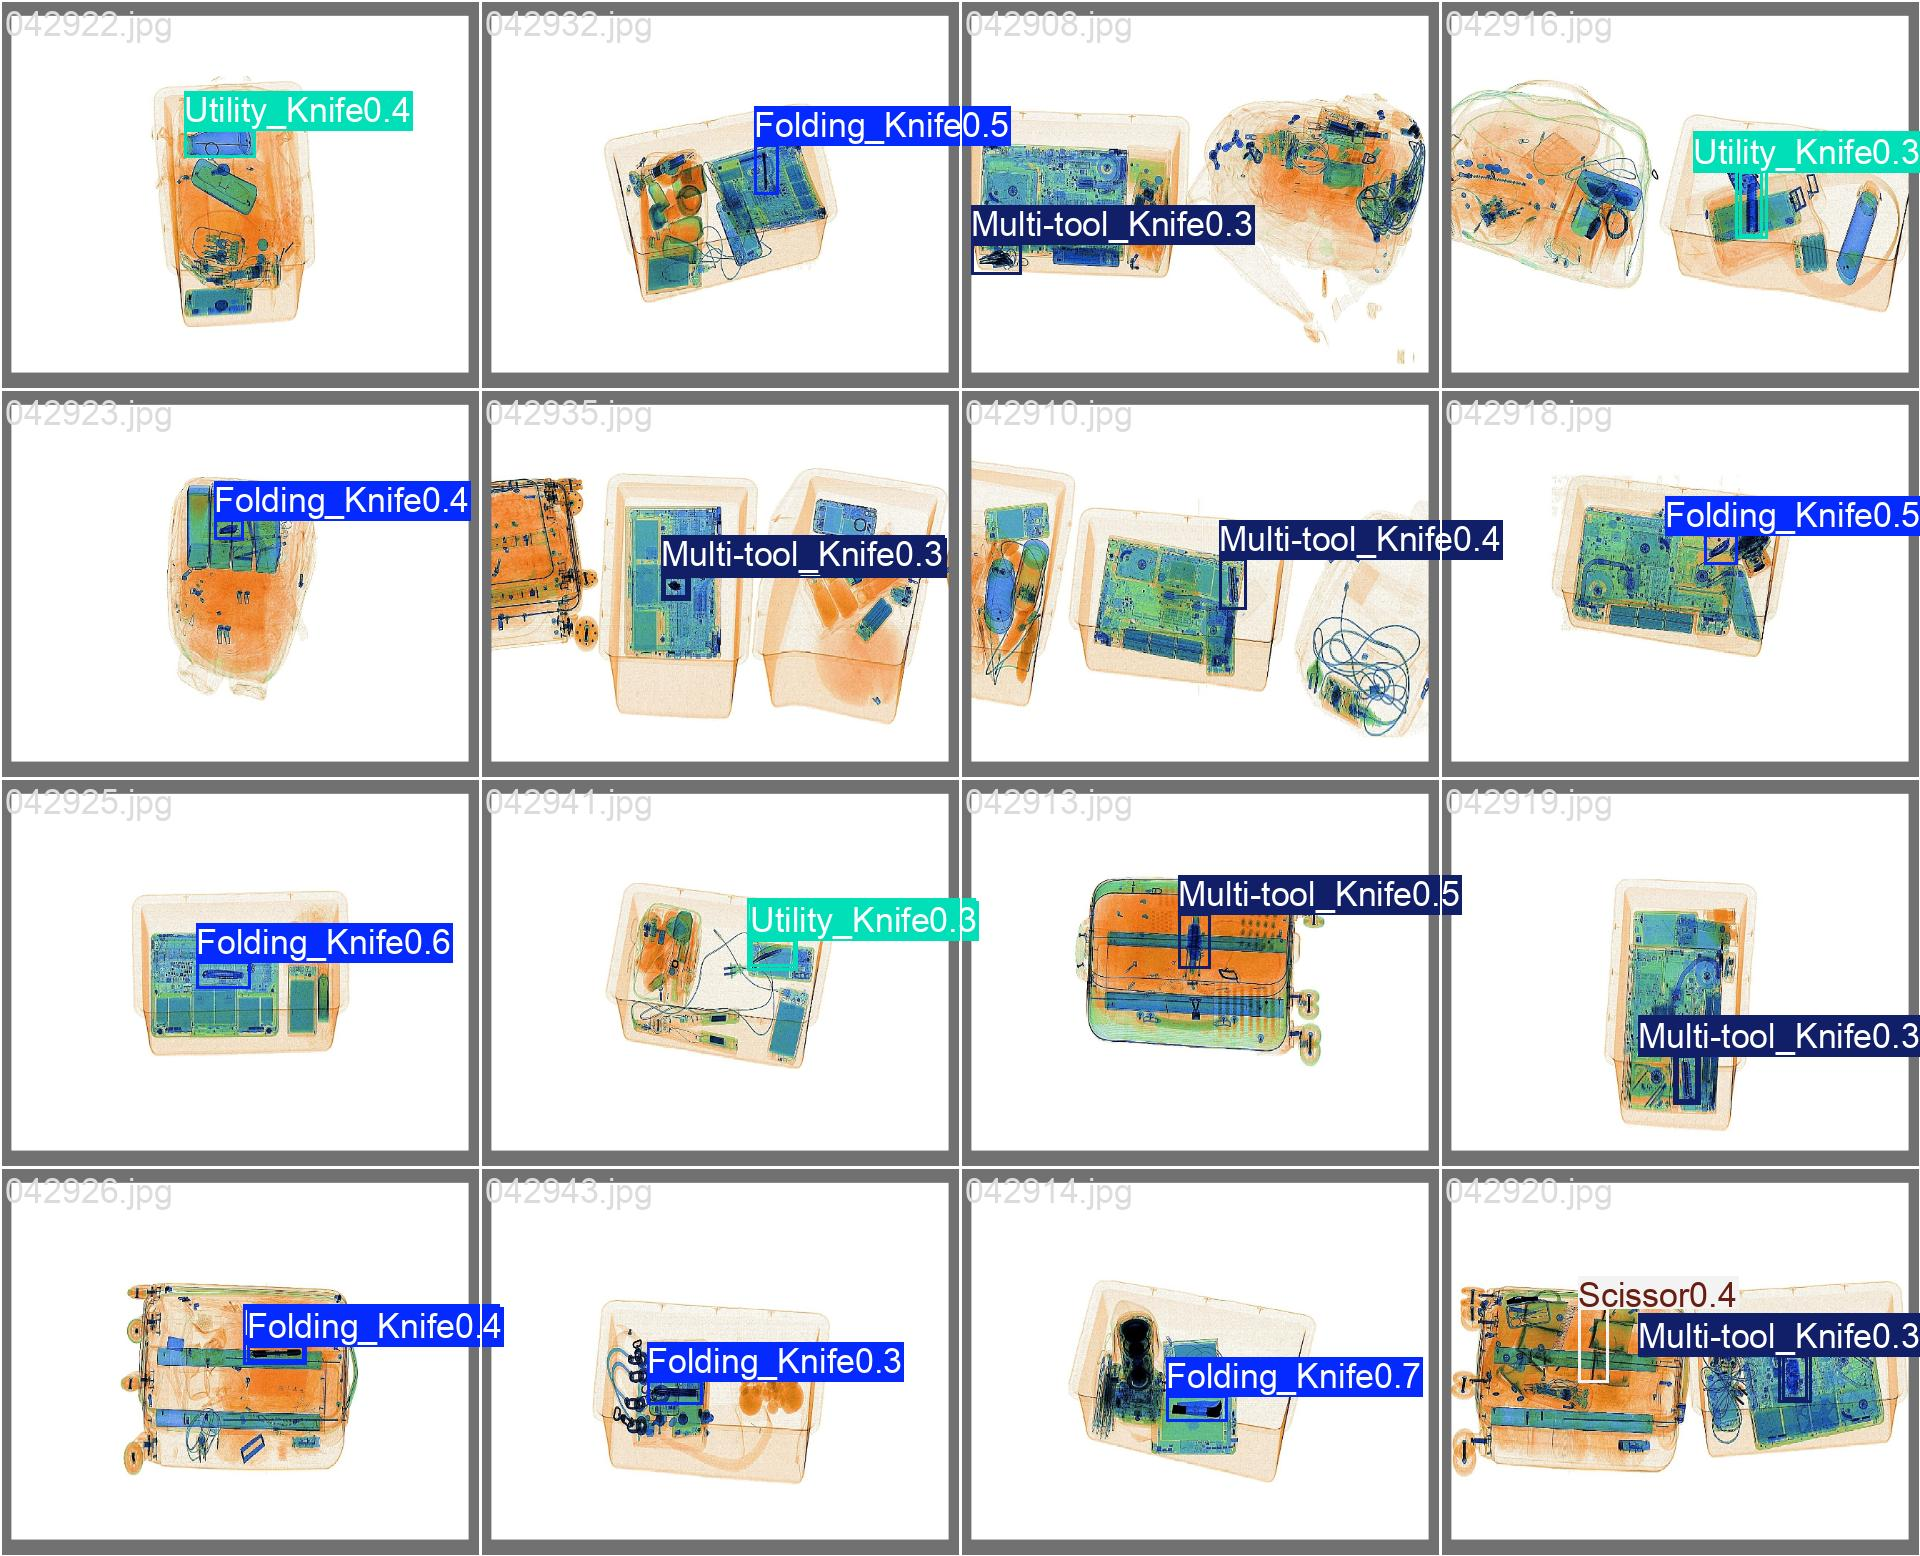

In [18]:
from pathlib import Path
from IPython.display import Image, display

results_dir = Path("/content/drive/MyDrive/opixray_full_yolov8n_20epochs_final")

sample_prediction = results_dir / "val_batch0_pred.jpg"

print("Prediction image exists:", sample_prediction.exists())
print("Prediction image path:", sample_prediction)

display(Image(filename=str(sample_prediction)))

## 12. Measure inference time and FPS on validation images

In [11]:
preprocess_ms = 0.3
inference_ms = 2.5
postprocess_ms = 2.4

total_time_ms = preprocess_ms + inference_ms + postprocess_ms
total_fps = 1000 / total_time_ms

print(f"Preprocess time: {preprocess_ms:.2f} ms/image")
print(f"Inference time: {inference_ms:.2f} ms/image")
print(f"Postprocess time: {postprocess_ms:.2f} ms/image")
print(f"Total processing time: {total_time_ms:.2f} ms/image")
print(f"End-to-end FPS: {total_fps:.2f} images/second")

Preprocess time: 0.30 ms/image
Inference time: 2.50 ms/image
Postprocess time: 2.40 ms/image
Total processing time: 5.20 ms/image
End-to-end FPS: 192.31 images/second
